# Load the hourly data & aggregate to weekly totals.

Hourly rows : 145,366
Date range  : 2002-01-01  →  2018-08-03

Duplicate timestamps  : 4
Rows after dedup      : 145,362
Missing values before : 0
Missing values after  : 0  ✓

Final hourly rows     : 145,392

                          MW
Datetime                    
2002-01-01 01:00:00  30393.0
2002-01-01 02:00:00  29265.0
2002-01-01 03:00:00  28357.0
2002-01-01 04:00:00  27899.0
2002-01-01 05:00:00  28057.0


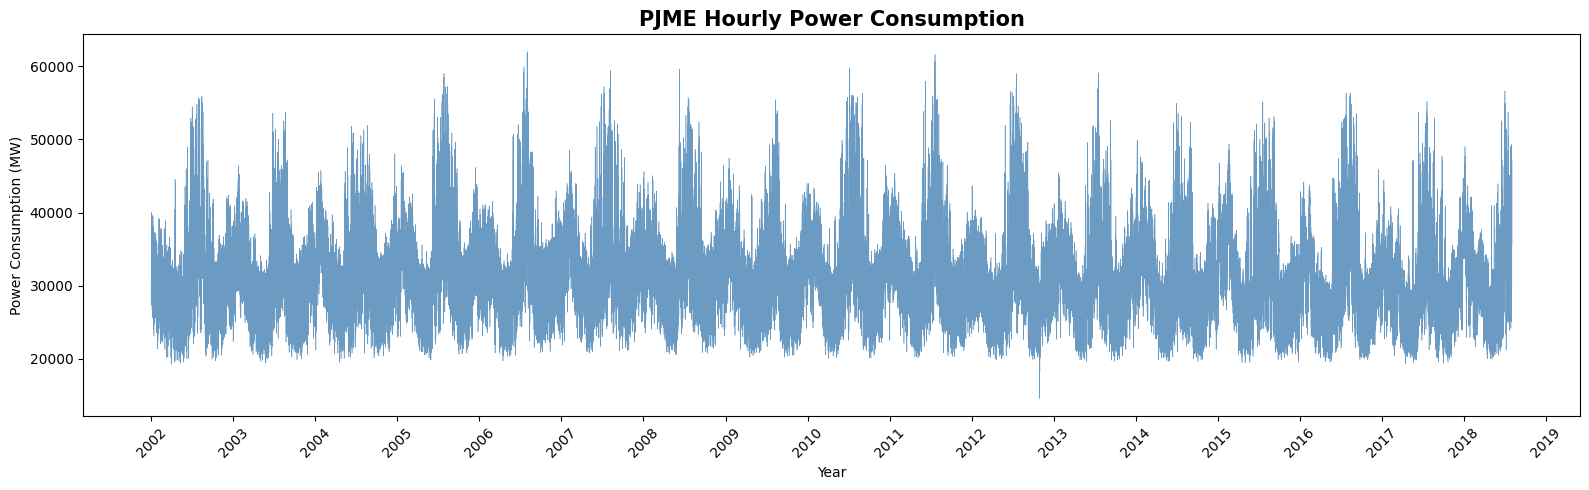

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

df_hourly = pd.read_csv('PJME_hourly.csv', parse_dates=['Datetime'], index_col='Datetime')
df_hourly.sort_index(inplace=True)
df_hourly.columns = ['MW']

print(f"Hourly rows : {len(df_hourly):,}")
print(f"Date range  : {df_hourly.index.min().date()}  →  {df_hourly.index.max().date()}")

# Average duplicate timestamps (keeps one row per hour)
duplicates = df_hourly.index.duplicated().sum()
print(f"\nDuplicate timestamps  : {duplicates}")
df_hourly = df_hourly.groupby(df_hourly.index).mean()
print(f"Rows after dedup      : {len(df_hourly):,}")

# Fill missing hours using linear interpolation
missing_before = df_hourly['MW'].isna().sum()
print(f"Missing values before : {missing_before}")

full_hourly_index = pd.date_range(
    start=df_hourly.index.min(),
    end=df_hourly.index.max(),
    freq='h',
    name='Datetime'
)
df_hourly = df_hourly.reindex(full_hourly_index)
df_hourly['MW'] = df_hourly['MW'].interpolate(method='linear').ffill().bfill()

missing_after = df_hourly['MW'].isna().sum()
print(f"Missing values after  : {missing_after}  ✓")
print(f"\nFinal hourly rows     : {len(df_hourly):,}")
print()
print(df_hourly.head())

fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(df_hourly.index, df_hourly['MW'],
        color='steelblue', linewidth=0.4, alpha=0.8)

ax.set_title('PJME Hourly Power Consumption', fontsize=15, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Power Consumption (MW)')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [15]:
# Sum 168 hourly readings per week and save
df_weekly = df_hourly.resample('W').sum()
df_weekly.columns = ['MW']

df_weekly.to_csv('PJME_weekly.csv')

print(f"Weekly rows : {len(df_weekly):,}  (saved → PJME_weekly.csv)")

Weekly rows : 866  (saved → PJME_weekly.csv)


## Load and plot weekly data



Weekly rows : 866
Date range  : 2002-01-06  →  2018-08-05

                   MW
Datetime             
2002-01-06  4632079.0
2002-01-13  5289881.0
2002-01-20  5284084.0
2002-01-27  5063777.0
2002-02-03  4905010.0


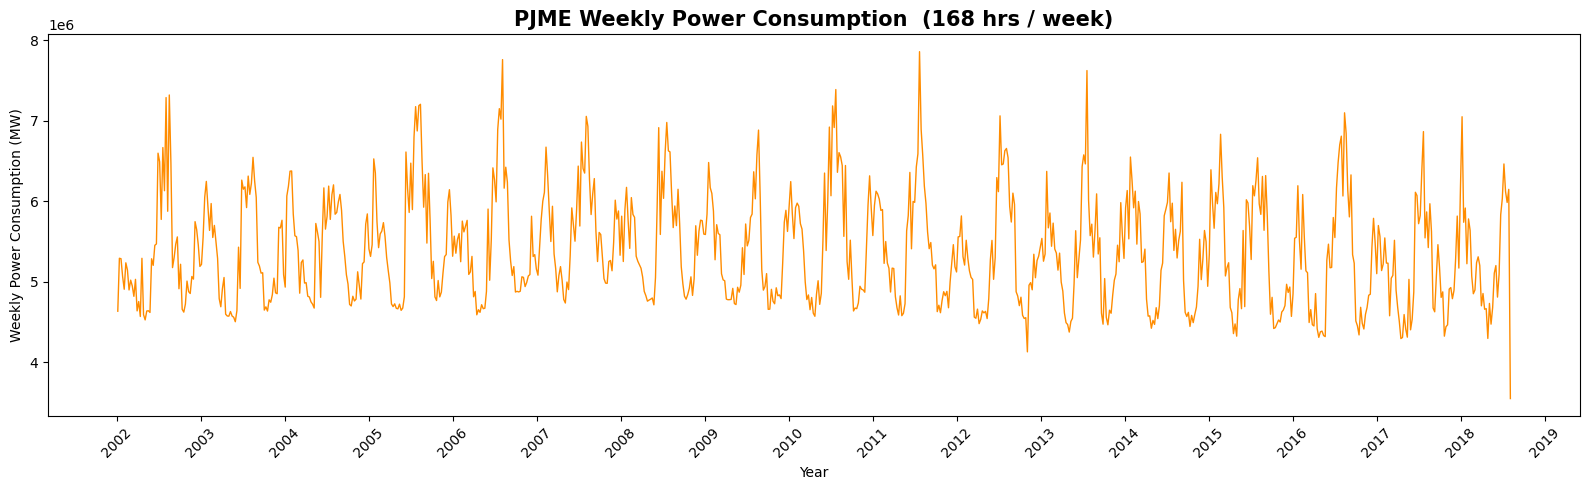

In [16]:
# Load the weekly CSV  
df = pd.read_csv('PJME_weekly.csv', index_col=0, parse_dates=True)
df.index.name = 'Datetime'
df.columns = ['MW']

print(f"Weekly rows : {len(df):,}")
print(f"Date range  : {df.index.min().date()}  →  {df.index.max().date()}")
print()
print(df.head())

# Plot the weekly data 
fig, ax = plt.subplots(figsize=(16, 5))

ax.plot(df.index, df['MW'],
        color='darkorange', linewidth=1.0)

ax.set_title('PJME Weekly Power Consumption  (168 hrs / week)', fontsize=15, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Weekly Power Consumption (MW)')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## Section 2 — Exploratory Visualizations

We examine the series from three angles:
1. **Time plot** — overall trend and long-run behaviour 
2. **Seasonal box plots** — distribution of consumption by month and by year  
3. **Rolling statistics** — visual check for changing mean / variance

C:\Users\naren\AppData\Local\Temp\ipykernel_10944\2008945945.py:12: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(monthly_data, labels=month_names, patch_artist=True,


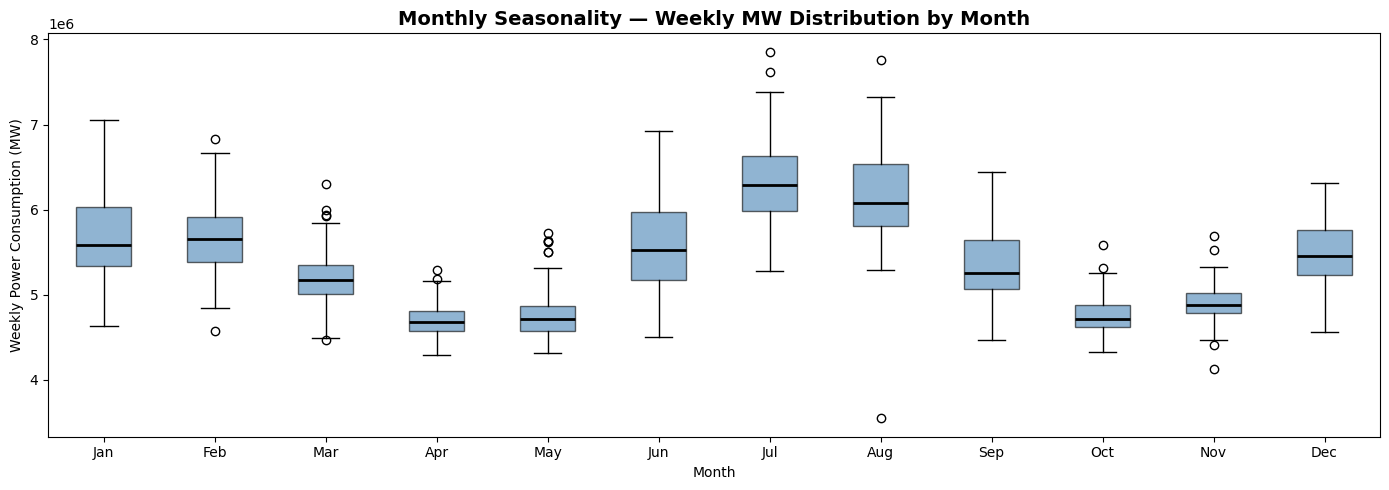

In [17]:
import numpy as np

# Seasonal Box Plot 1: Distribution of weekly MW by Month
df['month'] = df.index.month
df['year']  = df.index.year

month_names  = ['Jan','Feb','Mar','Apr','May','Jun',
                'Jul','Aug','Sep','Oct','Nov','Dec']
monthly_data = [df.loc[df['month'] == m, 'MW'].values for m in range(1, 13)]

fig, ax = plt.subplots(figsize=(14, 5))
ax.boxplot(monthly_data, labels=month_names, patch_artist=True,
           boxprops=dict(facecolor='steelblue', alpha=0.6),
           medianprops=dict(color='black', linewidth=2))
ax.set_title('Monthly Seasonality — Weekly MW Distribution by Month',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Weekly Power Consumption (MW)')
plt.tight_layout()
plt.show()


# Box Plot 2: Distribution of weekly MW by Year 

C:\Users\naren\AppData\Local\Temp\ipykernel_10944\115709382.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(yearly_data, labels=years, patch_artist=True,


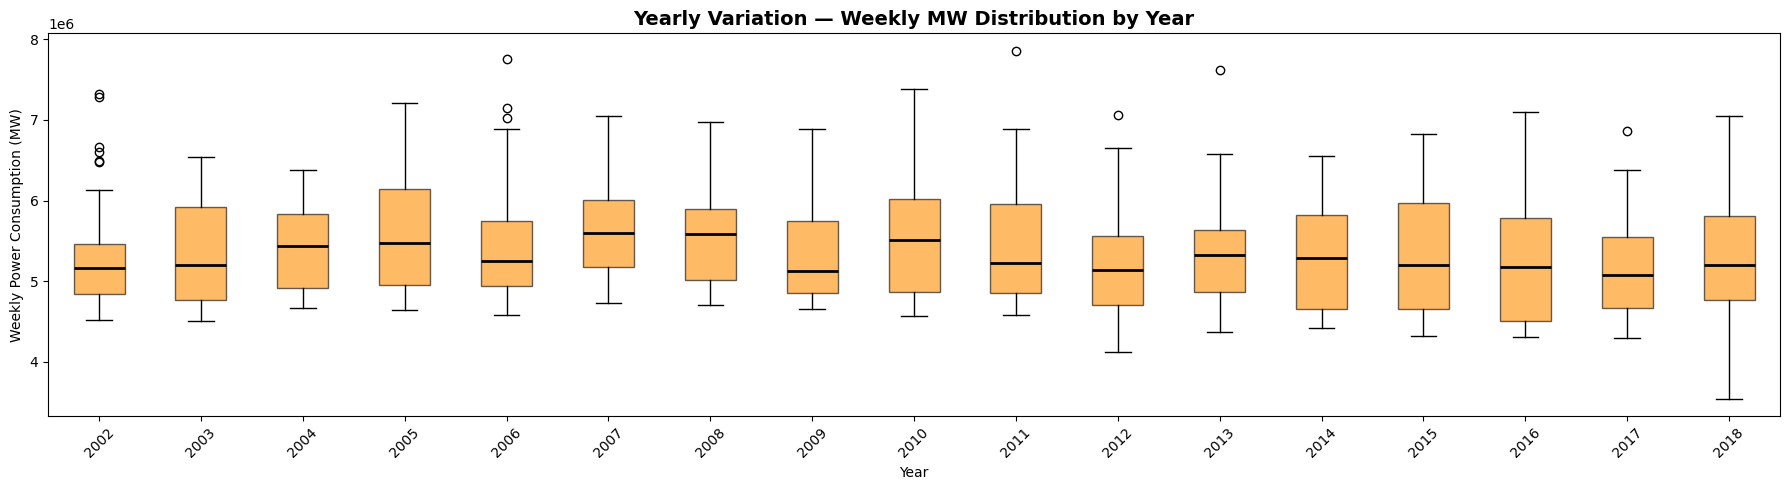

In [18]:
years       = sorted(df['year'].unique())
yearly_data = [df.loc[df['year'] == y, 'MW'].values for y in years]

fig, ax = plt.subplots(figsize=(18, 5))
ax.boxplot(yearly_data, labels=years, patch_artist=True,
           boxprops=dict(facecolor='darkorange', alpha=0.6),
           medianprops=dict(color='black', linewidth=2))
ax.set_title('Yearly Variation — Weekly MW Distribution by Year',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Year')
ax.set_ylabel('Weekly Power Consumption (MW)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

df.drop(columns=['month', 'year'], inplace=True)


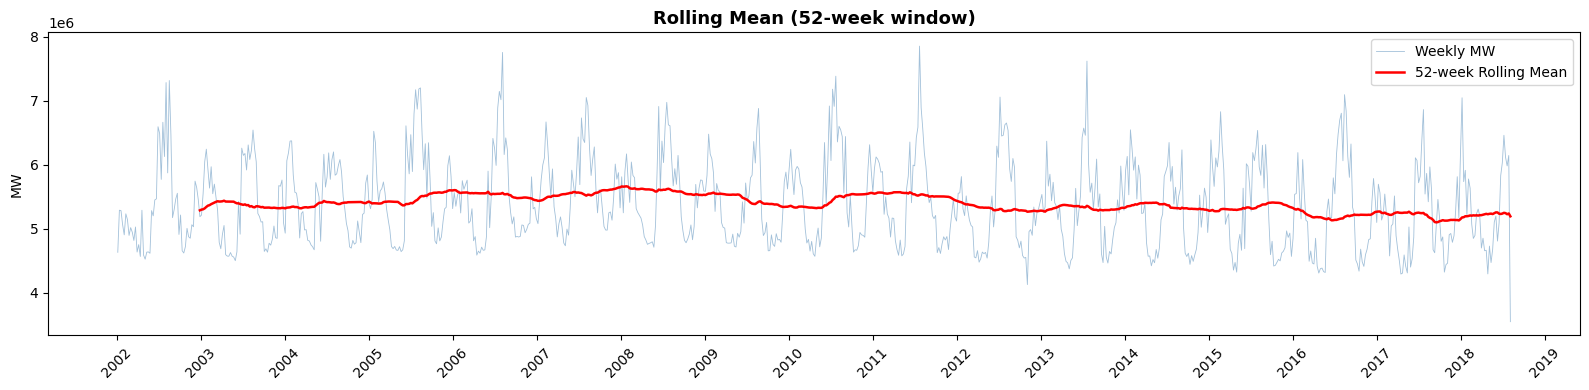

In [19]:
# Rolling Mean (52-week window ≈ 1 year)
rolling_mean = df['MW'].rolling(window=52).mean()

fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(df.index, df['MW'], color='steelblue', linewidth=0.6,
        alpha=0.5, label='Weekly MW')
ax.plot(rolling_mean.index, rolling_mean, color='red', linewidth=1.8,
        label='52-week Rolling Mean')
ax.set_title('Rolling Mean (52-week window)', fontsize=13, fontweight='bold')
ax.set_ylabel('MW')
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


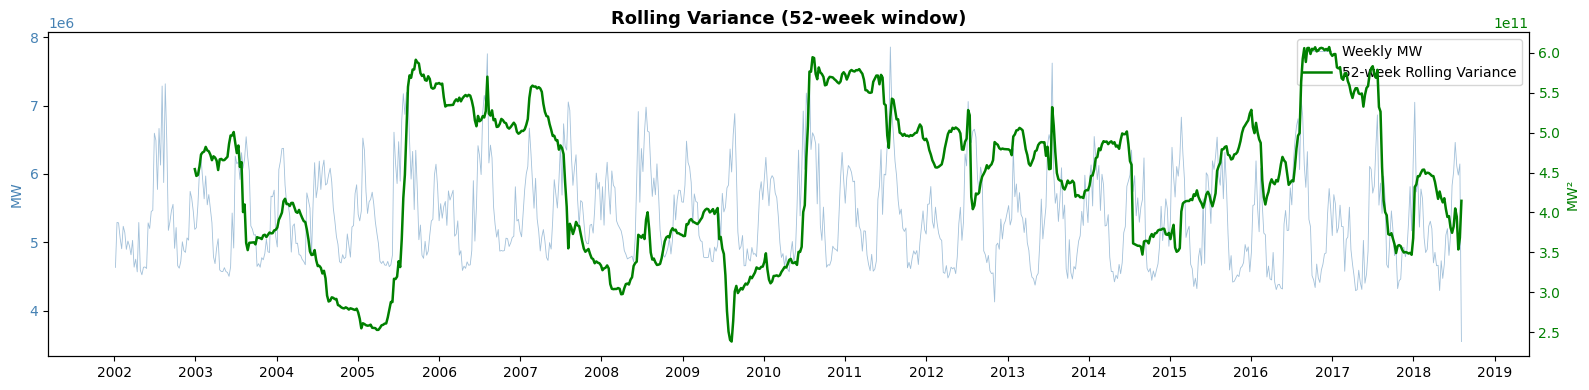

In [20]:
# Rolling Variance (52-week window ≈ 1 year)
rolling_var = df['MW'].rolling(window=52).var()

fig, ax_mw = plt.subplots(figsize=(16, 4))
ax_var = ax_mw.twinx()

ax_mw.plot(df.index, df['MW'], color='steelblue', linewidth=0.6,
           alpha=0.5, label='Weekly MW')
ax_var.plot(rolling_var.index, rolling_var, color='green', linewidth=1.8,
            label='52-week Rolling Variance')

ax_mw.set_title('Rolling Variance (52-week window)', fontsize=13, fontweight='bold')
ax_mw.set_ylabel('MW', color='steelblue')
ax_var.set_ylabel('MW²', color='green')
ax_mw.tick_params(axis='y', labelcolor='steelblue')
ax_var.tick_params(axis='y', labelcolor='green')

lines1, labels1 = ax_mw.get_legend_handles_labels()
lines2, labels2 = ax_var.get_legend_handles_labels()
ax_mw.legend(lines1 + lines2, labels1 + labels2)

ax_mw.xaxis.set_major_locator(mdates.YearLocator())
ax_mw.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


- **Trend** — long-run direction of power consumption  
- **Seasonality** — repeating annual cycle (period = 52 weeks)  
- **Residual / Noise** — what remains after removing trend and season

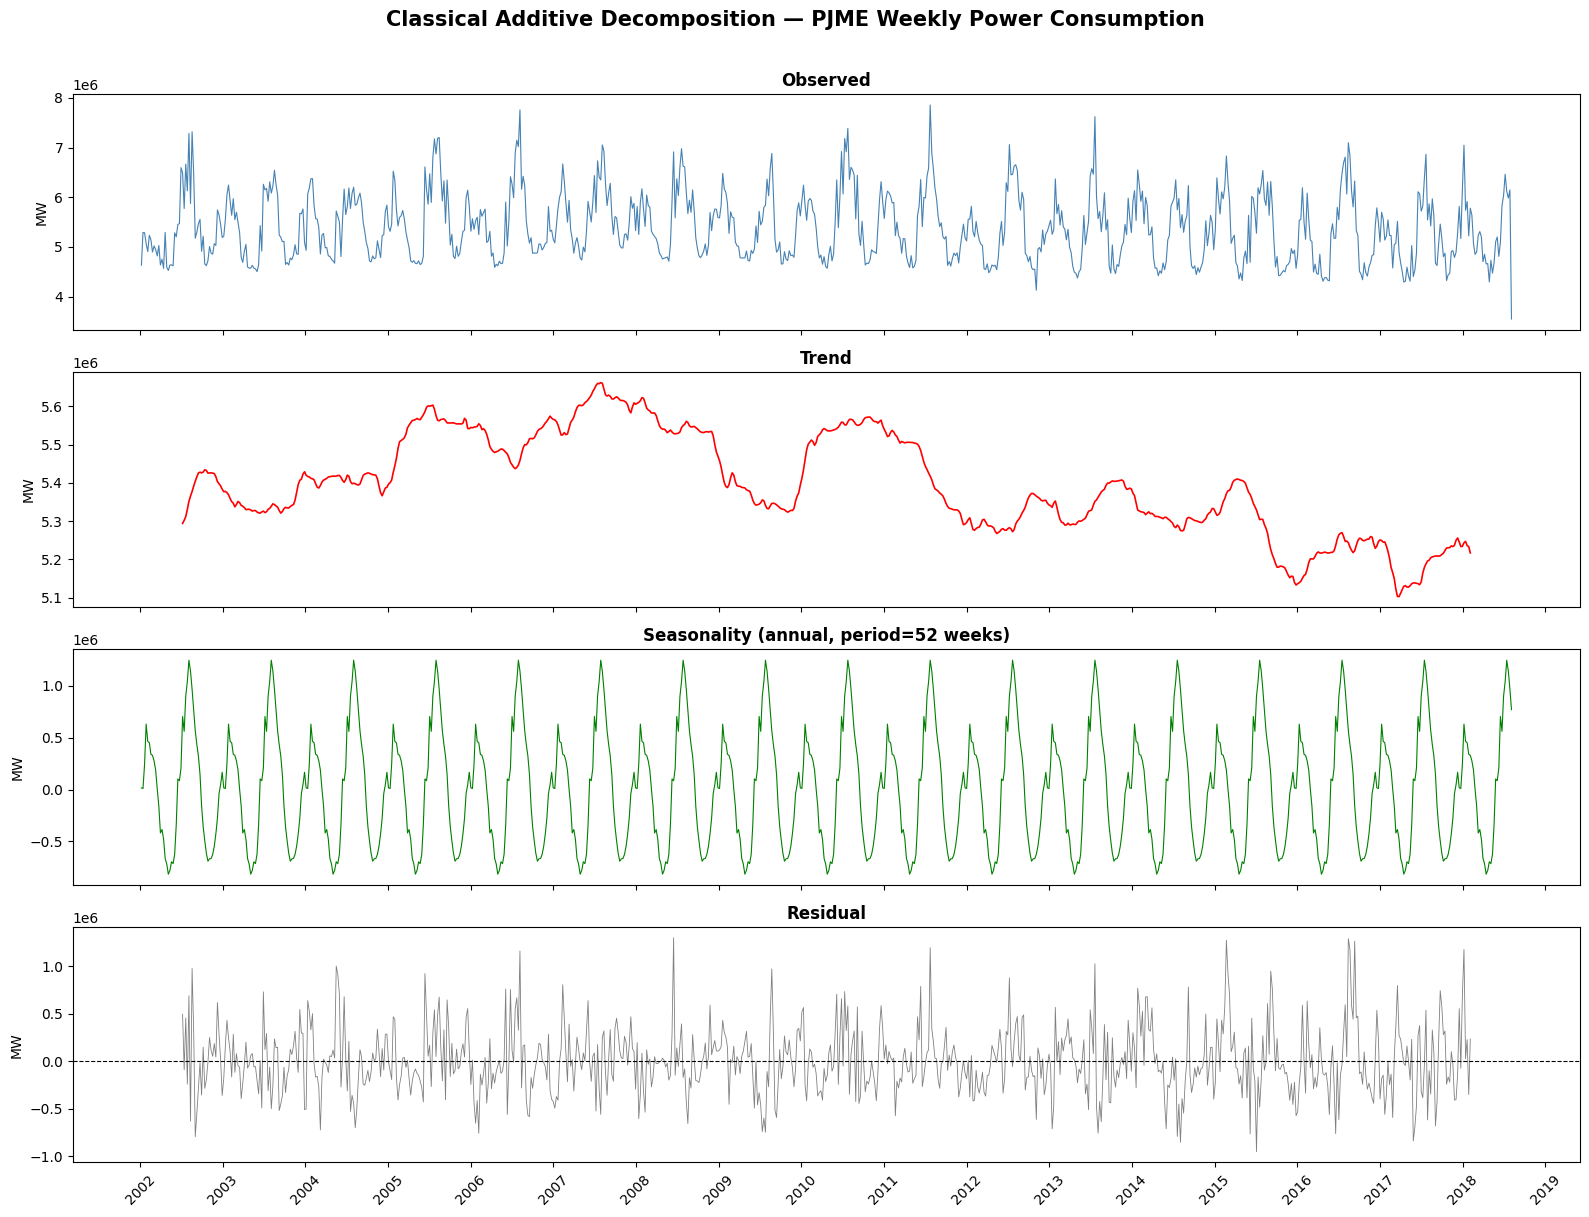

In [21]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Additive model: assumes seasonal amplitude is roughly constant over time
# period=52 weeks corresponds to one annual cycle
decomposition = seasonal_decompose(df['MW'], model='additive', period=52)

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)

axes[0].plot(df.index, df['MW'],                    color='steelblue', linewidth=0.8)
axes[0].set_title('Observed',  fontweight='bold')
axes[0].set_ylabel('MW')

axes[1].plot(decomposition.trend.index,   decomposition.trend,    color='red',    linewidth=1.2)
axes[1].set_title('Trend',     fontweight='bold')
axes[1].set_ylabel('MW')

axes[2].plot(decomposition.seasonal.index, decomposition.seasonal, color='green',  linewidth=0.8)
axes[2].set_title('Seasonality (annual, period=52 weeks)', fontweight='bold')
axes[2].set_ylabel('MW')

axes[3].plot(decomposition.resid.index,   decomposition.resid,    color='grey',   linewidth=0.6)
axes[3].axhline(0, color='black', linewidth=0.8, linestyle='--')
axes[3].set_title('Residual',  fontweight='bold')
axes[3].set_ylabel('MW')

for ax in axes:
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

plt.xticks(rotation=45)
fig.suptitle('Classical Additive Decomposition — PJME Weekly Power Consumption',
             fontsize=15, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()



##  Stationarity Tests
### ADF Test



In [22]:
from statsmodels.tsa.stattools import adfuller, kpss

series = df['MW'].dropna()

adf_result  = adfuller(series, autolag='AIC')
adf_stat, adf_pval, adf_lags, adf_nobs = adf_result[:4]
adf_critical = adf_result[4]

print("  Augmented Dickey-Fuller (ADF) Test")
print("=" * 55)
print(f"  Test Statistic   : {adf_stat:.4f}")
print(f"  p-value          : {adf_pval:.4f}")
print(f"  Lags used        : {adf_lags}")
for level, val in adf_critical.items():
    print(f"  Critical ({level})  : {val:.4f}")
print()
if adf_pval < 0.05:
    print("   RESULT: Reject H₀, Series is STATIONARY (ADF)")
else:
    print("   RESULT: Fail to reject H₀, Series is NON-STATIONARY (ADF)")


  Augmented Dickey-Fuller (ADF) Test
  Test Statistic   : -12.3993
  p-value          : 0.0000
  Lags used        : 11
  Critical (1%)  : -3.4380
  Critical (5%)  : -2.8649
  Critical (10%)  : -2.5686

   RESULT: Reject H₀, Series is STATIONARY (ADF)


### KPSS Test

In [23]:
kpss_result = kpss(series, regression='c', nlags='auto')
kpss_stat, kpss_pval, kpss_lags, kpss_critical = kpss_result

print("  KPSS Test")
print("=" * 55)
print(f"  Test Statistic   : {kpss_stat:.4f}")
print(f"  p-value          : {kpss_pval:.4f}")
print(f"  Lags used        : {kpss_lags}")
for level, val in kpss_critical.items():
    print(f"  Critical ({level})  : {val:.4f}")
print()
if kpss_pval < 0.05:
    print("   RESULT: Reject H₀, Series is NON-STATIONARY (KPSS)")
else:
    print("   RESULT: Fail to reject H₀, Series is STATIONARY (KPSS)")


  KPSS Test
  Test Statistic   : 0.3636
  p-value          : 0.0928
  Lags used        : 16
  Critical (10%)  : 0.3470
  Critical (5%)  : 0.4630
  Critical (2.5%)  : 0.5740
  Critical (1%)  : 0.7390

   RESULT: Fail to reject H₀, Series is STATIONARY (KPSS)


## Autocorrelation Analysis - ACF & PACF

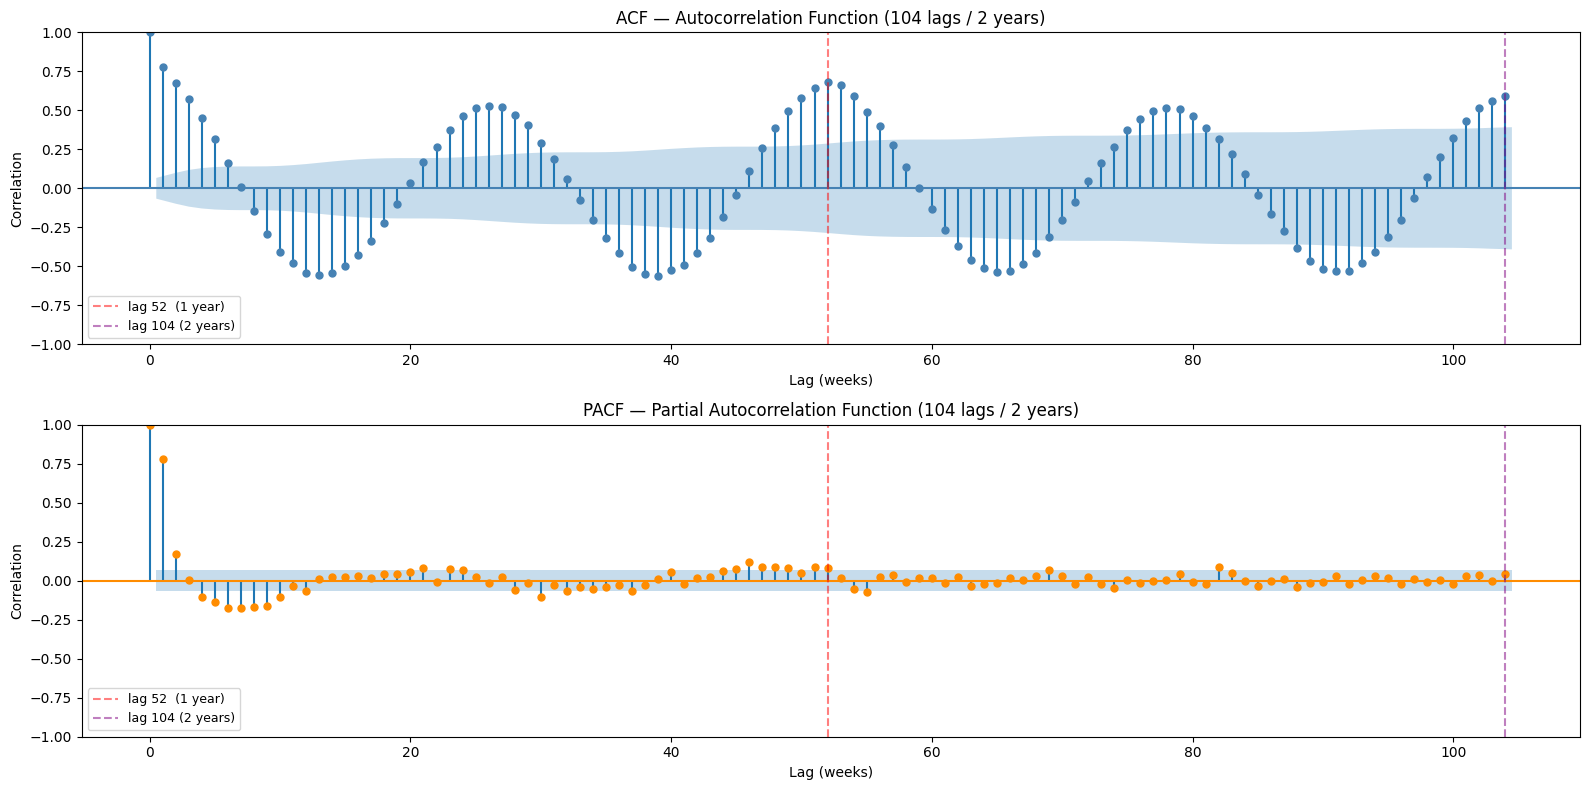

In [24]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(16, 8))

# 104 lags = 2 years of weekly data
plot_acf(series,  lags=104, ax=axes[0], color='steelblue',
         title='ACF — Autocorrelation Function (104 lags / 2 years)')

plot_pacf(series, lags=104, ax=axes[1], color='darkorange', method='ywm',
          title='PACF — Partial Autocorrelation Function (104 lags / 2 years)')

for ax in axes:
    ax.set_xlabel('Lag (weeks)')
    ax.set_ylabel('Correlation')
    ax.axvline(x=52,  color='red',    linestyle='--', alpha=0.5, label='lag 52  (1 year)')
    ax.axvline(x=104, color='purple', linestyle='--', alpha=0.5, label='lag 104 (2 years)')
    ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

### Train/Test Split

Train  :  730 weeks  (2002-01-06 → 2015-12-27)
Test   :  136 weeks  (2016-01-03  → 2018-08-05)


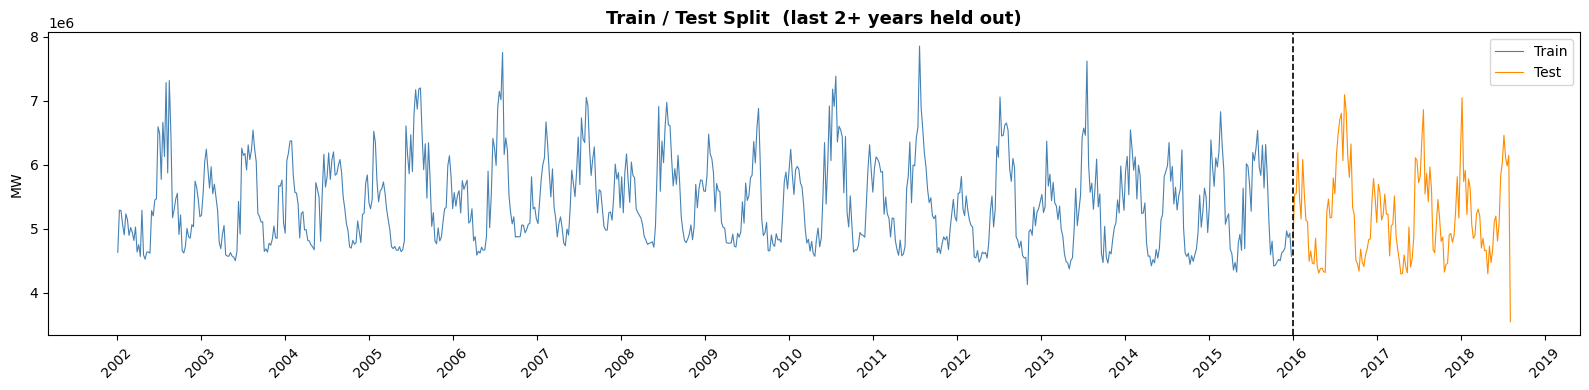

In [25]:
# last ~2 years (104 weeks) as the test set
SPLIT_DATE = '2016-01-03'   # first Sunday of 2016

train = df.loc[df.index <  SPLIT_DATE]
test  = df.loc[df.index >= SPLIT_DATE]

print(f"Train  : {len(train):>4} weeks  ({train.index.min().date()} → {train.index.max().date()})")
print(f"Test   : {len(test):>4} weeks  ({test.index.min().date()}  → {test.index.max().date()})")

fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(train.index, train['MW'], color='steelblue',  linewidth=0.8, label='Train')
ax.plot(test.index,  test['MW'],  color='darkorange', linewidth=0.8, label='Test')
ax.axvline(pd.Timestamp(SPLIT_DATE), color='black', linestyle='--', linewidth=1.2)
ax.set_title('Train / Test Split  (last 2+ years held out)', fontsize=13, fontweight='bold')
ax.set_ylabel('MW')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
ax.legend()
plt.tight_layout()
plt.show()

## Linear Time Series Model - SARIMA
#### SARIMA(1,1,1)(1,1,1)[52]


In [26]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_model = SARIMAX(train['MW'],
                       order=(1, 1, 0),
                       seasonal_order=(1, 1, 0, 52),
                       enforce_stationarity=False,
                       enforce_invertibility=False)

sarima_result = sarima_model.fit(disp=False)
print(sarima_result.summary())


d:\System\Conda\envs\absa\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)
d:\System\Conda\envs\absa\lib\site-packages\statsmodels\tsa\base\tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency W-SUN will be used.
  self._init_dates(dates, freq)


                                     SARIMAX Results                                      
Dep. Variable:                                 MW   No. Observations:                  730
Model:             SARIMAX(1, 1, 0)x(1, 1, 0, 52)   Log Likelihood               -9007.748
Date:                            Sat, 07 Mar 2026   AIC                          18021.497
Time:                                    06:10:39   BIC                          18034.805
Sample:                                01-06-2002   HQIC                         18026.669
                                     - 12-27-2015                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3496      0.039     -9.016      0.000      -0.426      -0.274
ar.S.L52      -0.4739      0.037   

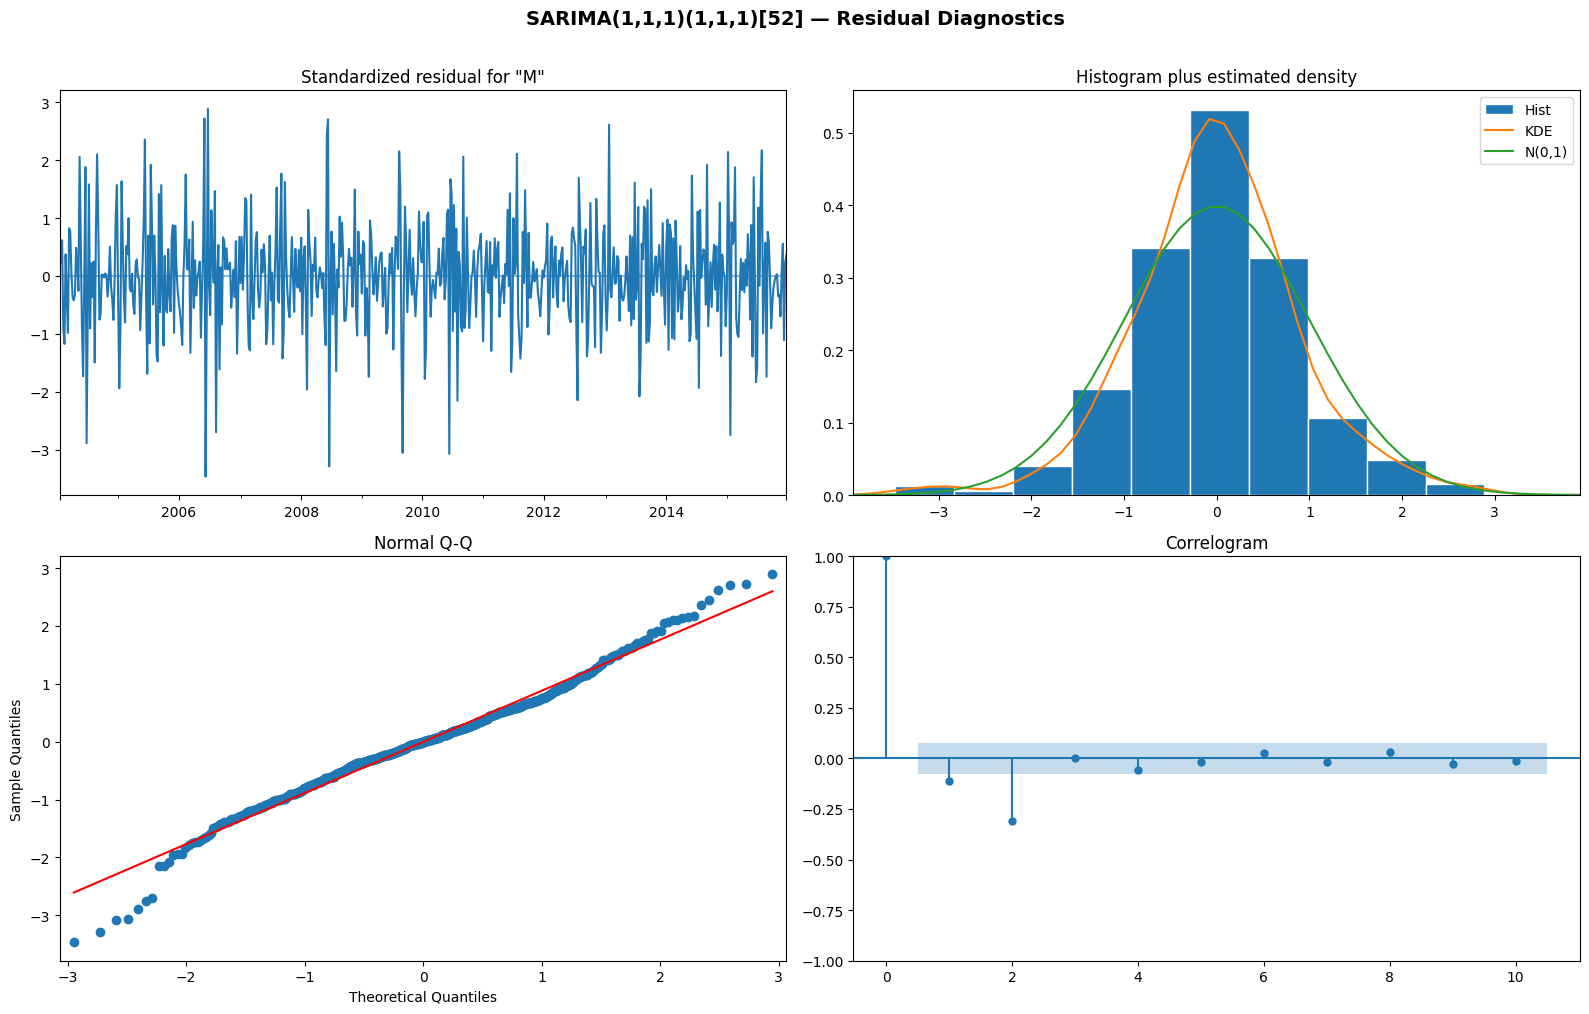

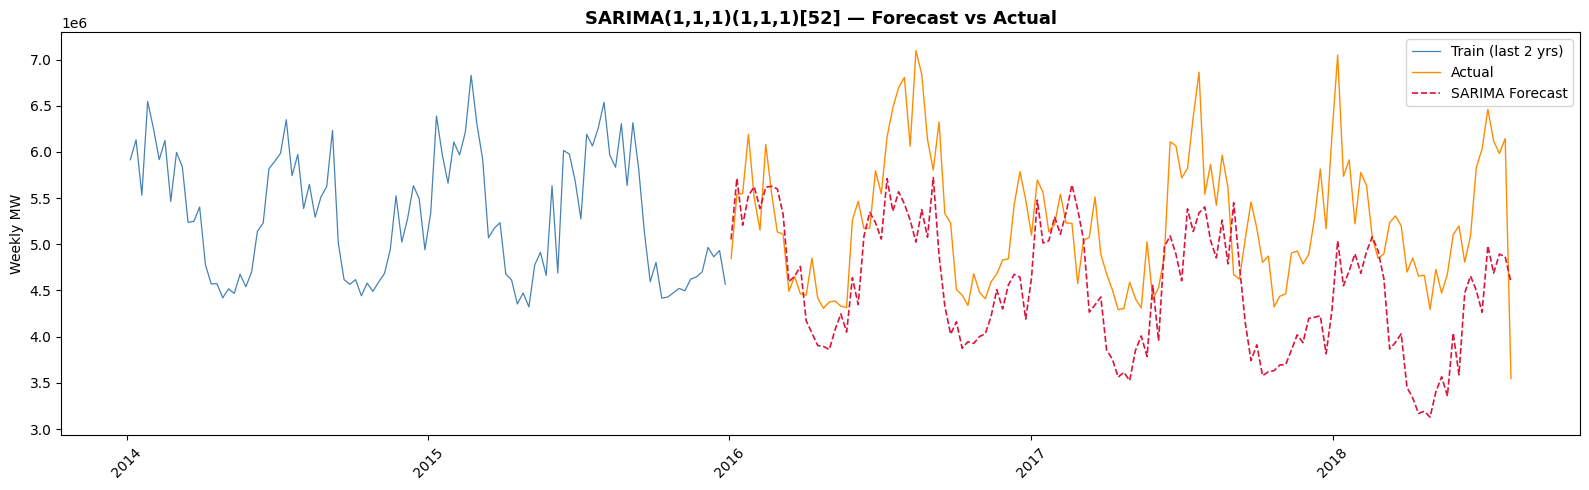

In [27]:
sarima_result.plot_diagnostics(figsize=(16, 10))
plt.suptitle('SARIMA(1,1,1)(1,1,1)[52] — Residual Diagnostics',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Forecast over the entire test period
sarima_forecast = sarima_result.get_forecast(steps=len(test))
sarima_pred     = sarima_forecast.predicted_mean
sarima_ci       = sarima_forecast.conf_int(alpha=0.05)

sarima_pred.index = test.index
sarima_ci.index   = test.index

fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(train.index[-104:], train['MW'].iloc[-104:],
        color='steelblue', linewidth=0.9, label='Train (last 2 yrs)')
ax.plot(test.index, test['MW'],
        color='darkorange', linewidth=1.0, label='Actual')
ax.plot(sarima_pred.index, sarima_pred,
        color='crimson', linewidth=1.2, linestyle='--', label='SARIMA Forecast')
ax.set_title('SARIMA(1,1,1)(1,1,1)[52] — Forecast vs Actual', fontsize=13, fontweight='bold')
ax.set_ylabel('Weekly MW')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
ax.legend()
plt.tight_layout()
plt.show()


In [28]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Reusable metrics function used by every model
def eval_metrics(actual, predicted, label):
    mae  = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mape = np.mean(np.abs((actual - np.asarray(predicted)) / actual)) * 100
    print(f"{label}")
    print(f"  MAE   : {mae:,.1f} MW")
    print(f"  RMSE  : {rmse:,.1f} MW")
    print(f"  MAPE  : {mape:.2f} %")
    print()
    return mae, rmse, mape

print("SARIMA(1,1,1)(1,1,1)[52] — Test Set Performance")
print("=" * 50)
eval_metrics(test['MW'], sarima_pred, 'SARIMA(1,1,1)(1,1,1)[52]')
print(f"  AIC   : {sarima_result.aic:,.1f}")
print(f"  BIC   : {sarima_result.bic:,.1f}")


SARIMA(1,1,1)(1,1,1)[52] — Test Set Performance
SARIMA(1,1,1)(1,1,1)[52]
  MAE   : 775,620.8 MW
  RMSE  : 920,940.7 MW
  MAPE  : 14.62 %

  AIC   : 18,021.5
  BIC   : 18,034.8


## SARIMA Parameter Tuning

**Approach:** `auto_arima` (from `pmdarima`) performs a **stepwise AIC-minimising search** over candidate (p, d, q)(P, D, Q)[52] orders.

- Stepwise search is used (instead of full grid search) to keep runtime manageable with S=52
- d and D are determined automatically via unit-root tests
- The best model by AIC is then compared against the manually specified SARIMA(1,1,1)(1,1,1)[52]


In [29]:
from pmdarima import auto_arima

# Stepwise AIC search over candidate SARIMA orders
# d=1, D=1 fixed from stationarity tests; m=52 for annual seasonality
auto_result = auto_arima(
    train['MW'],
    start_p=0, start_q=0, max_p=2, max_q=2,
    start_P=0, start_Q=0, max_P=2, max_Q=2,
    d=0, D=0,
    seasonal=True, m=52,
    stepwise=True,
    information_criterion='aic',
    error_action='ignore',
    suppress_warnings=True,
    trace=True
)

print()
print("Best order selected by auto_arima:")
print(f"  SARIMA{auto_result.order}{auto_result.seasonal_order}")
print(f"  AIC : {auto_result.aic():.1f}")


Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[52] intercept   : AIC=21646.126, Time=0.08 sec
 ARIMA(1,0,0)(1,0,0)[52] intercept   : AIC=20884.242, Time=50.07 sec
 ARIMA(0,0,1)(0,0,1)[52] intercept   : AIC=21257.602, Time=4.15 sec
 ARIMA(0,0,0)(0,0,0)[52]             : AIC=24721.800, Time=0.05 sec
 ARIMA(1,0,0)(0,0,0)[52] intercept   : AIC=20928.580, Time=0.05 sec
 ARIMA(1,0,0)(2,0,0)[52] intercept   : AIC=inf, Time=146.80 sec
 ARIMA(1,0,0)(1,0,1)[52] intercept   : AIC=inf, Time=30.06 sec
 ARIMA(1,0,0)(0,0,1)[52] intercept   : AIC=20902.531, Time=3.77 sec
 ARIMA(1,0,0)(2,0,1)[52] intercept   : AIC=20908.987, Time=194.57 sec
 ARIMA(0,0,0)(1,0,0)[52] intercept   : AIC=21643.209, Time=12.22 sec
 ARIMA(2,0,0)(1,0,0)[52] intercept   : AIC=20856.438, Time=60.57 sec
 ARIMA(2,0,0)(0,0,0)[52] intercept   : AIC=20908.714, Time=0.16 sec
 ARIMA(2,0,0)(2,0,0)[52] intercept   : AIC=inf, Time=204.39 sec
 ARIMA(2,0,0)(1,0,1)[52] intercept   : AIC=inf, Time=58.53 sec
 ARIMA(2,0,0)(0,0,

KeyboardInterrupt: 

In [ ]:

# Best model found by auto_arima: SARIMA(1,1,2)(2,1,0)[52]
best_order          = (1, 1, 2)
best_seasonal_order = (2, 1, 0, 52)

best_model = SARIMAX(train['MW'],
                     order=best_order,
                     seasonal_order=best_seasonal_order,
                     enforce_stationarity=False,
                     enforce_invertibility=False)

best_result = best_model.fit(disp=False)

best_forecast = best_result.get_forecast(steps=len(test))
best_pred     = best_forecast.predicted_mean
best_pred.index = test.index

print(f"Fine-Tuned SARIMA{best_order}{best_seasonal_order} — Test Set Performance")
print("=" * 50)
eval_metrics(test['MW'], best_pred, f'SARIMA{best_order}{best_seasonal_order}  [best AIC]')
print(f"  AIC   : {best_result.aic:,.1f}")
print(f"  BIC   : {best_result.bic:,.1f}")

# Comparison plot: SARIMA(1,1,1)(1,1,1)[52] vs Fine-Tuned SARIMA vs Actual
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(train.index[-104:], train['MW'].iloc[-104:],
        color='steelblue', linewidth=0.9, label='Train (last 2 yrs)')
ax.plot(test.index, test['MW'],
        color='darkorange', linewidth=1.2, label='Actual')
ax.plot(sarima_pred.index, sarima_pred,
        color='crimson', linewidth=1.2, linestyle='--', label='SARIMA(1,1,1)(1,1,1)[52]')
ax.plot(best_pred.index, best_pred,
        color='mediumblue', linewidth=1.2, linestyle='--',
        label=f'SARIMA{best_order}{best_seasonal_order}  [best AIC]')
ax.set_title('SARIMA vs Fine-Tuned SARIMA vs Actual', fontsize=13, fontweight='bold')
ax.set_ylabel('Weekly MW')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
ax.legend()
plt.tight_layout()
plt.show()


## Non-Linear Time Series Models - SETAR

In [ ]:
# SETAR splits the series into two regimes based on a threshold on the lagged difference.
# Each regime gets its own AR model, fitted using OLS.

from sklearn.linear_model import LinearRegression

diff_train = train['MW'].diff().dropna().values  # first differences of training MW
all_levels = df['MW'].values
train_len  = len(train)

# Build AR(1) design matrix on first differences: X = [1, Δy(t-1)], y = Δy(t)
X_tr  = np.column_stack([np.ones(len(diff_train) - 1), diff_train[:-1]])
Y_tr  = diff_train[1:]
thr_v = diff_train[:-1]

# Split into low/high regime by median of the threshold variable
threshold = float(np.median(thr_v))
mask_low  = thr_v <= threshold
mask_high = thr_v >  threshold

lr_low  = LinearRegression().fit(X_tr[mask_low],  Y_tr[mask_low])
lr_high = LinearRegression().fit(X_tr[mask_high], Y_tr[mask_high])

print(f"Threshold  = {threshold:.1f} MW / week")
print(f"Regime LOW  (ΔMW ≤ threshold) — {mask_low.sum():>4} obs   AR coef = {lr_low.coef_[1]:.4f}")
print(f"Regime HIGH (ΔMW >  threshold) — {mask_high.sum():>4} obs   AR coef = {lr_high.coef_[1]:.4f}")

# 1-step-ahead forecast: predict Δy, then add to previous actual level
preds_level = []
for i in range(len(test)):
    idx        = train_len + i
    prev_level = all_levels[idx - 1]
    prev_diff  = all_levels[idx - 1] - all_levels[idx - 2]
    feat       = np.array([[1.0, prev_diff]])
    d_pred     = lr_low.predict(feat)[0] if prev_diff <= threshold else lr_high.predict(feat)[0]
    preds_level.append(prev_level + d_pred)

setar_pred = pd.Series(preds_level, index=test.index, name='SETAR(2,1)')

print(f"\nSETAR(2,1) — Test Performance")
print("=" * 45)
eval_metrics(test['MW'], setar_pred, 'SETAR(2,1)')

fig, ax = plt.subplots(figsize=(16, 4))
ax.plot(test.index, test['MW'],  lw=1.0, color='darkorange', label='Actual')
ax.plot(test.index, setar_pred,  lw=1.0, color='seagreen', linestyle='--', label='SETAR(2,1)')
ax.set_title('SETAR(2,1) — 1-Step-Ahead Forecast vs Actual', fontsize=12, fontweight='bold')
ax.set_ylabel('MW')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
ax.legend()
plt.tight_layout()
plt.show()


### Data Preprocessing for DL Model

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Reload data if kernel was restarted
if 'train' not in dir() or 'test' not in dir():
    df = pd.read_csv('PJME_weekly.csv', index_col=0, parse_dates=True)
    df.index.name = 'Datetime'
    df.columns = ['MW']
    SPLIT_DATE = '2016-01-03'
    train = df.loc[df.index <  SPLIT_DATE]
    test  = df.loc[df.index >= SPLIT_DATE]
    print(f"Data reloaded — train: {len(train)} weeks, test: {len(test)} weeks")

LOOKBACK = 52  # one year of weekly lags

# Scale to [0,1] — fit on train only to prevent data leakage
scaler = MinMaxScaler(feature_range=(0, 1))
train_scaled = scaler.fit_transform(train[['MW']])
test_scaled  = scaler.transform(test[['MW']])

def make_sequences(arr, lookback):
    """Convert a scaled array into (X, y) sliding-window sequences."""
    X, y = [], []
    for i in range(lookback, len(arr)):
        X.append(arr[i - lookback:i, 0])
        y.append(arr[i, 0])
    return np.array(X)[..., np.newaxis], np.array(y)

X_train, y_train = make_sequences(train_scaled, LOOKBACK)

# For test sequences, prepend the last LOOKBACK train points to avoid leakage
full_scaled  = np.vstack([train_scaled, test_scaled])
X_test, y_test = make_sequences(full_scaled[len(train_scaled) - LOOKBACK:], LOOKBACK)

# Last 52 train weeks held out as validation
X_val, y_val = X_train[-LOOKBACK:], y_train[-LOOKBACK:]
X_train_f, y_train_f = X_train[:-LOOKBACK], y_train[:-LOOKBACK]

print(f"X_train : {X_train_f.shape}   y_train : {y_train_f.shape}")
print(f"X_val   : {X_val.shape}       y_val   : {y_val.shape}")
print(f"X_test  : {X_test.shape}      y_test  : {y_test.shape}")


## LSTM

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

tf.random.set_seed(42)

# Stacked LSTM: first layer captures short-range patterns, second captures longer-range
model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(LOOKBACK, 1)),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dense(1)
], name='LSTM_energy')

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3), loss='mse')
model.summary()

# Stop early if validation loss stops improving; restore the best weights
early_stop = EarlyStopping(monitor='val_loss', patience=15,
                           restore_best_weights=True, verbose=1)

history = model.fit(
    X_train_f, y_train_f,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=16,
    callbacks=[early_stop],
    verbose=0
)

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history.history['loss'],     label='Train loss (MSE)')
ax.plot(history.history['val_loss'], label='Val loss (MSE)')
ax.set_title('LSTM — Training & Validation Loss', fontweight='bold')
ax.set_xlabel('Epoch')
ax.set_ylabel('MSE (scaled)')
ax.legend()
plt.tight_layout()
plt.show()

print(f"Best epoch : {np.argmin(history.history['val_loss']) + 1}")

In [ ]:
# Predict all test weeks in one pass, then inverse-scale back to MW
y_pred_scaled = model.predict(X_test, verbose=0)
lstm_pred_vals = scaler.inverse_transform(y_pred_scaled).flatten()
lstm_pred = pd.Series(lstm_pred_vals, index=test.index, name='LSTM')

print("LSTM — Test Set Performance")
print("=" * 45)
_, rmse_l, _ = eval_metrics(test['MW'], lstm_pred, 'LSTM(64-32)')

# Forecast plot
fig, ax = plt.subplots(figsize=(16, 5))
ax.plot(test.index, test['MW'],  color='darkorange', lw=1.2, label='Actual')
ax.plot(test.index, lstm_pred,   color='mediumorchid', lw=1.2,
        linestyle='--', label=f'LSTM  (RMSE={rmse_l:,.0f} MW)')
ax.set_title('LSTM — Forecast vs Actual (Test Set)', fontsize=13, fontweight='bold')
ax.set_ylabel('Weekly MW')
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
plt.xticks(rotation=45)
ax.legend()
plt.tight_layout()
plt.show()


## Models Comparison Table

In [ ]:
_act = test['MW'].values

def get_metrics(pred):
    mae  = mean_absolute_error(_act, pred)
    rmse = np.sqrt(mean_squared_error(_act, pred))
    mape = np.mean(np.abs((_act - np.asarray(pred)) / _act)) * 100
    return round(mae, 1), round(rmse, 1), round(mape, 2)

results = {
    'SARIMA(1,1,1)(1,1,1)[52]':       get_metrics(sarima_pred),
    'SARIMA(1,1,2)(2,1,0)[52] [best AIC]': get_metrics(best_pred),
    'SETAR(2,1)':                      get_metrics(setar_pred),
    'LSTM(64-32)':                     get_metrics(lstm_pred),
}

comparison_df = pd.DataFrame(
    results,
    index=['MAE (MW)', 'RMSE (MW)', 'MAPE (%)']
).T

print("\nModel Comparison — Test Set Performance")
print("=" * 55)
print(comparison_df.to_string())
